In [44]:


import numpy as np
import pandas as pd 



In [45]:
df = pd.read_csv('train.csv')

In [46]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
df['TotalIndoorArea'] = df['GrLivArea'] + df['TotalBsmtSF']
df['TotalOutdoorArea'] = df['WoodDeckSF'] + df['OpenPorchSF']

redundant_cols = [
    'GrLivArea', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 
    'BsmtFinSF1', 'BsmtUnfSF', 'WoodDeckSF', 'OpenPorchSF', 'GarageArea'
]

df = df.drop(redundant_cols, axis=1, errors='ignore')

In [49]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF2,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,TotalIndoorArea,TotalOutdoorArea
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,46.549315,...,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890,2572.893151,140.904795
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,161.319273,...,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883,823.598492,145.168739
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000,334.000000,0.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000,2014.000000,0.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000,2479.000000,112.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000,3008.500000,228.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,1474.000000,...,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000,11752.000000,929.000000


In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 74 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Id                1460 non-null   int64  
 1   MSSubClass        1460 non-null   int64  
 2   MSZoning          1460 non-null   str    
 3   LotFrontage       1201 non-null   float64
 4   LotArea           1460 non-null   int64  
 5   Street            1460 non-null   str    
 6   Alley             91 non-null     str    
 7   LotShape          1460 non-null   str    
 8   LandContour       1460 non-null   str    
 9   Utilities         1460 non-null   str    
 10  LotConfig         1460 non-null   str    
 11  LandSlope         1460 non-null   str    
 12  Neighborhood      1460 non-null   str    
 13  Condition1        1460 non-null   str    
 14  Condition2        1460 non-null   str    
 15  BldgType          1460 non-null   str    
 16  HouseStyle        1460 non-null   str    
 17  Overal

In [51]:
df = df.drop(['Id','PoolQC','Fence','MiscFeature','FireplaceQu','MasVnrType','Alley'],axis=1)

In [52]:
from sklearn.model_selection import train_test_split
x = df.drop('SalePrice',axis = 1)
y = df['SalePrice']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [53]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 1168 entries, 254 to 1126
Data columns (total 66 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MSSubClass        1168 non-null   int64  
 1   MSZoning          1168 non-null   str    
 2   LotFrontage       951 non-null    float64
 3   LotArea           1168 non-null   int64  
 4   Street            1168 non-null   str    
 5   LotShape          1168 non-null   str    
 6   LandContour       1168 non-null   str    
 7   Utilities         1168 non-null   str    
 8   LotConfig         1168 non-null   str    
 9   LandSlope         1168 non-null   str    
 10  Neighborhood      1168 non-null   str    
 11  Condition1        1168 non-null   str    
 12  Condition2        1168 non-null   str    
 13  BldgType          1168 non-null   str    
 14  HouseStyle        1168 non-null   str    
 15  OverallQual       1168 non-null   int64  
 16  OverallCond       1168 non-null   int64  
 17  YearBuilt

In [54]:
num_cols = x_train.select_dtypes(include=['int64','float64']).columns
var_cols = x_train.select_dtypes(include=['object']).columns

C:\Users\MASHALLAH\AppData\Local\Temp\ipykernel_2100\3186678016.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  var_cols = x_train.select_dtypes(include=['object']).columns


In [55]:
train_median = x_train[num_cols].median()
train_mode = x_train[var_cols].mode().iloc[0]

In [56]:
x_train[num_cols] = x_train[num_cols].fillna(train_median)
x_train[var_cols] = x_train[var_cols].fillna(train_mode)

In [57]:
x_test[num_cols] = x_test[num_cols].fillna(train_median)
x_test[var_cols] = x_test[var_cols].fillna(train_mode)

In [58]:
x_train.isnull().sum()

MSSubClass          0
MSZoning            0
LotFrontage         0
LotArea             0
Street              0
                   ..
YrSold              0
SaleType            0
SaleCondition       0
TotalIndoorArea     0
TotalOutdoorArea    0
Length: 66, dtype: int64

In [59]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output = False,handle_unknown = 'ignore')

In [60]:
train_encoded_array = encoder.fit_transform(x_train[var_cols])
train_encoded_df = pd.DataFrame(train_encoded_array, columns = encoder.get_feature_names_out(var_cols))

In [61]:
test_encoded_array = encoder.transform(x_test[var_cols])
test_encoded_df = pd.DataFrame(test_encoded_array, columns = encoder.get_feature_names_out(var_cols))

In [62]:
x_train = x_train.drop(var_cols,axis=1).reset_index(drop= True)
train_encoded_df = train_encoded_df.reset_index(drop=True)
x_train = pd.concat([x_train,train_encoded_df],axis = 1)

In [63]:
x_test = x_test.drop(var_cols,axis=1).reset_index(drop= True)
test_encoded_df = test_encoded_df.reset_index(drop=True)
x_test = pd.concat([x_test,test_encoded_df],axis = 1)

In [64]:
x_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Columns: 257 entries, MSSubClass to SaleCondition_Partial
dtypes: float64(231), int64(26)
memory usage: 2.3 MB


In [65]:
x_train.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF2,LowQualFinSF,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,20,70.0,8400,5,6,1957,1957,0.0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,60,59.0,7837,6,7,1993,1994,0.0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,30,67.0,8777,5,7,1910,1950,0.0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,50,60.0,7200,5,7,1937,1950,252.0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,50,50.0,5000,5,6,1924,1950,0.0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [66]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [67]:
model = RandomForestRegressor(random_state=42)

In [68]:
model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [69]:
prediction = model.predict(x_test)

In [70]:
mae = mean_absolute_error(y_test,prediction)
print(f"Mean Absolute Error: ${mae:,.2f}")

Mean Absolute Error: $18,274.77


In [71]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, prediction)
print(f"R-squared Score: {r2:.2f}")

R-squared Score: 0.88


In [76]:
import matplotlib.pyplot as plt

In [77]:
importances = model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature':x_train.columns,
    'importance':importances
})

In [78]:
top_features = feature_importance_df.sort_values(by='importance',ascending=False).head(20)

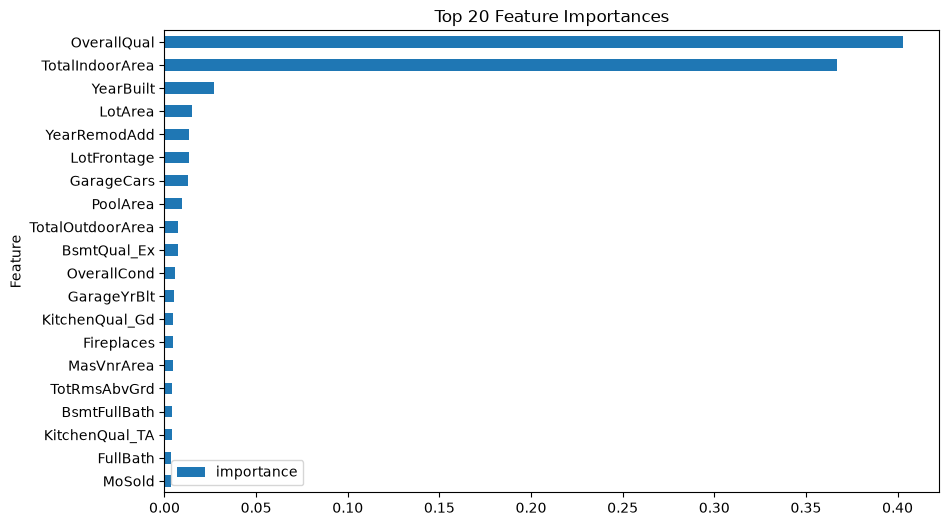

In [80]:
top_features.set_index('Feature').sort_values(by='importance').plot(kind='barh', figsize=(10, 6), title='Top 20 Feature Importances')
plt.show()

In [81]:
import joblib

# 1. Save the trained Random Forest model
joblib.dump(model, 'rf_house_model.joblib')

# 2. Save the One-Hot Encoder (Critical for the backend to process text inputs)
joblib.dump(encoder, 'house_encoder.joblib')

# 3. Save the list of exact columns the model expects (useful for the FastAPI setup)
joblib.dump(list(x_train.columns), 'model_columns.joblib')

print("Files successfully exported for the FastAPI backend!")

Files successfully exported for the FastAPI backend!
